# Big Data e IA · Práctica 1 · Echando un vistazo a los terremotos (paso a paso)
**Nombre y apellidos:**

Gitbook: *Unidad 2 → Echando un vistazo* → https://ies-sh-iabigdata.gitbook.io/iabigdata/unidad-2-preprocesamiento-de-datos/echando-un-vistazo
Datos: terremotos del **último mes** en todo el mundo (USGS), los mismos de la Actividad 21.

### Cómo trabajar
1. Abre la página del gitbook en otra pestaña: cada paso de este cuaderno es un apartado de la página aplicado a los terremotos.
2. Lee el **📌 Tarea**, **sustituye los `___`** y ejecuta.
3. Mira el **✅ Comprueba**. Como los datos son del último mes, **tus números pueden ser algo distintos** a los del compañero de otro día: es normal, los datos están vivos.
4. Responde las **❓ preguntas**: en el examen se pregunta **qué hace el código** y **qué se ve en un gráfico**.

La página tiene 3 apartados: **(1)** ver los datos con funciones, **(2)** gráficos con pandas, Matplotlib y Seaborn, **(3)** visualización en Big Data.

---
# Paso 0 · Librerías
Ejecuta sin cambiar nada. Si `seaborn` da error, ejecuta en una celda `!pip install seaborn` y vuelve a probar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# Apartado 1 · Ver los datos con funciones (repaso del Tutorial 21)
## Paso 1 · Cargar el CSV desde la URL
📌 **Tarea:** carga el CSV con `read_csv` y mira su tamaño.
💡 **Pista:** `read_csv` puede leer **directamente de una URL**.
✅ **Comprueba:** unas **8.000–12.000 filas** y **22 columnas**.

⚠️ **Si da error de conexión:** abre `https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/all_month.csv` en el navegador, se descarga `all_month.csv`. Ponlo en la misma carpeta que este cuaderno y usa `pd.read_csv("all_month.csv")`.

In [5]:
url = "https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/all_month.csv"
terremotos = pd.read_csv(url)
print(terremotos.shape)

(9818, 22)


## Paso 2 · La fecha viene como texto
📌 **Tarea:** convierte la columna `time` a fecha y muestra las columnas que nos interesan.
✅ **Comprueba:** `time` pasa de `object` a `datetime64[...]`.

In [6]:
print("Antes:", terremotos["time"].dtype)
terremotos["time"] = pd.to_datetime(terremotos["time"])
print("Después:", terremotos["time"].dtype)

terremotos[["time", "latitude", "longitude", "depth", "mag", "type", "place"]].head()

Antes: str
Después: datetime64[us, UTC]


,time,latitude,longitude,depth,mag,type,place
0,2026-11-11 19:00:51.409000+00:00,59.985000,-152.433000,75.30,2.00,earthquake,"39 km W of Happy Valley, Alaska"
1,2026-11-11 18:56:33.370000+00:00,38.814499,-122.800835,2.82,0.75,earthquake,"6 km NW of The Geysers, CA"
2,2026-11-11 18:45:23.510000+00:00,40.109165,-121.357330,12.82,1.77,earthquake,"14 km NW of Belden, CA"
3,2026-11-11 18:28:12.880000+00:00,35.693330,-117.548170,6.15,1.05,earthquake,"14 km NE of Ridgecrest, CA"
4,2026-11-11 18:04:36.601000+00:00,58.290000,-154.983000,5.00,1.10,earthquake,"86 km NNW of Karluk, Alaska"


❓ **Pregunta 2:** ¿qué significa cada columna? Completa: `depth` = ______ · `mag` = ______ · `place` = ______

*Tu respuesta:*

## Paso 3 · Tipos y nulos con `info()`
📌 **Tarea:** ejecuta `info()`.
❓ **Pregunta 3:** mira **Non-Null Count**. ¿Tiene nulos la columna `mag`? ¿Y `latitude`? Nombra una columna con muchos nulos.

*Tu respuesta:*

In [ ]:
terremotos.info()

# La columna con mas nulos es horizontalError

<class 'pandas.DataFrame'>
RangeIndex: 9818 entries, 0 to 9817
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   time             9818 non-null   datetime64[us, UTC]
 1   latitude         9818 non-null   float64            
 2   longitude        9818 non-null   float64            
 3   depth            9818 non-null   float64            
 4   mag              9818 non-null   float64            
 5   magType          9818 non-null   str                
 6   nst              9818 non-null   int64              
 7   gap              9818 non-null   float64            
 8   dmin             9814 non-null   float64            
 9   rms              9818 non-null   float64            
 10  net              9818 non-null   str                
 11  id               9818 non-null   str                
 12  updated          9818 non-null   str                
 13  place            9817 non-nul

## Paso 4 · Estadísticas con `describe()`
📌 **Tarea:** estadísticas solo de `mag` y `depth`.
❓ **Pregunta 4:** ¿cuál es la magnitud media? ¿Y la mediana (fila `50%`)? ¿Qué profundidad máxima hay?

*Tu respuesta:*

In [8]:
terremotos[["mag", "depth"]].describe()

,mag,depth
count,9818.000000,9818.000000
mean,1.803499,24.653243
std,1.267968,57.890996
min,-1.540000,-3.410000
25%,1.000000,3.612500
50%,1.610000,8.412450
75%,2.200000,17.400000
max,7.000000,651.227000


## Paso 5 · ¿Todo son terremotos? `value_counts()`
📌 **Tarea:** cuenta cuántos eventos hay de cada `type`.

In [9]:
terremotos["type"].value_counts()

type
earthquake      9574
quarry blast     112
explosion         87
ice quake         41
other event        3
landslide          1
Name: count, dtype: int64

❓ **Pregunta 5:** ¿qué otros tipos de evento aparecen además de `earthquake`?

*Tu respuesta:*

## Paso 6 · El mayor terremoto del mes
📌 **Tarea:** ejecuta y explica qué hace cada parte.

In [14]:
fila = terremotos["mag"].idxmax() # selecciona el valor máximo de la fila terremoto
terremotos.loc[fila, ["time", "mag", "place"]] # del pd terremotos se selecciona el 
    #de mayor magnitud, se muestra su hora, magnitud y lugar,
    #  accediendo por el nombre de la fila en este caso

time     2026-10-22 14:33:40.289000+00:00
mag                                   7.0
place          189 km ENE of Nagqu, China
Name: 6199, dtype: object

❓ **Pregunta 6:** ¿qué devuelve `idxmax()`: el valor de la magnitud o el número de fila? ¿Para qué sirve después `loc`?

*Tu respuesta:* Devuelve el valor maximo de la fila y el loc nos permite localizar una fila en base a ese nombre que nos retorna el idxmax que hemos seleccionado antes

---
# Apartado 2 · Gráficos con pandas y Matplotlib
## Paso 7 · Histograma (página: `df['edad'].hist(bins=10)`)
📌 **Tarea:** histograma de la magnitud con 30 tramos.

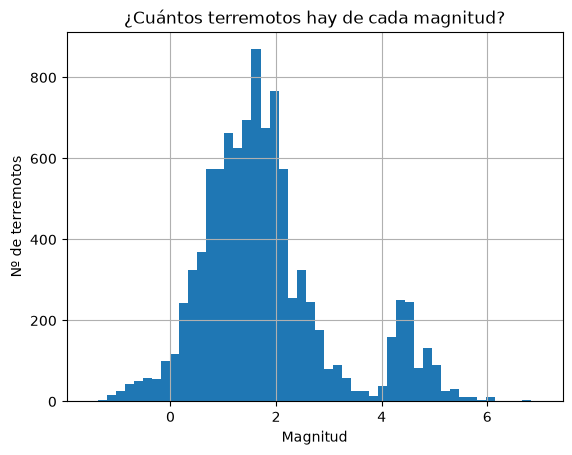

In [20]:
terremotos["mag"].hist(bins=50)
plt.title("¿Cuántos terremotos hay de cada magnitud?")
plt.xlabel("Magnitud"); plt.ylabel("Nº de terremotos")
plt.show()

❓ **Pregunta 7:** ¿hay más terremotos pequeños o grandes? ¿Qué pasa si cambias `bins=30` por `bins=5`?

*Tu respuesta:*

## Paso 8 · Boxplot (página: `df.boxplot(column='ingreso')`)
📌 **Tarea:** boxplot de la profundidad (`depth`) y, debajo, su `describe()`.

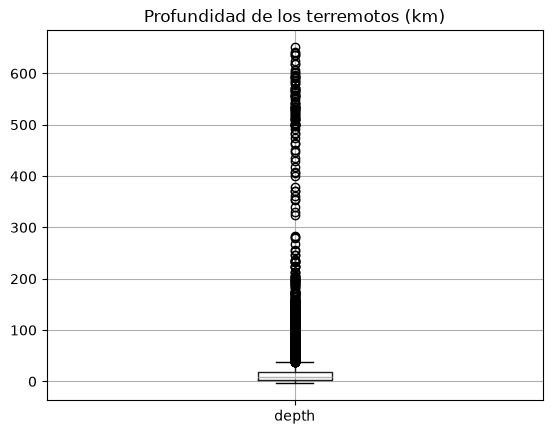

count    9818.000000
mean       24.653243
std        57.890996
min        -3.410000
25%         3.612500
50%         8.412450
75%        17.400000
max       651.227000
Name: depth, dtype: float64

In [13]:
terremotos.boxplot(column="depth")
plt.title("Profundidad de los terremotos (km)")
plt.show()

terremotos["depth"].describe()

❓ **Pregunta 8:** ¿qué son los puntos sueltos de arriba? Las tres rayas de la caja, ¿con qué filas del `describe` coinciden?

```
   ── máximo (sin outliers)
   ┌─┐ ← 75 %
   │─│ ← mediana (50 %)
   └─┘ ← 25 %
   ── mínimo
   ●   ← outlier
```
*Tu respuesta:* Significa que tengo tantos valores fuera de la media/diagrama que distorsiona el dibujo. No dejan de ser outliers. Las 3 rayas son 

## Paso 9 · Línea (página: `df['ventas'].plot(kind='line')`)
📌 **Tarea:** cuenta los terremotos de cada día y dibuja la línea.
💡 **Pista:** `dt.date` se queda solo con el día; `value_counts()` cuenta; `sort_index()` ordena por fecha.

time
2026-10-12 19:09:26.114000+00:00    1
2026-10-12 19:11:55.225000+00:00    1
2026-10-12 19:24:59.270000+00:00    1
2026-10-12 19:25:10.140000+00:00    1
2026-10-12 19:37:19.110000+00:00    1
Name: count, dtype: int64


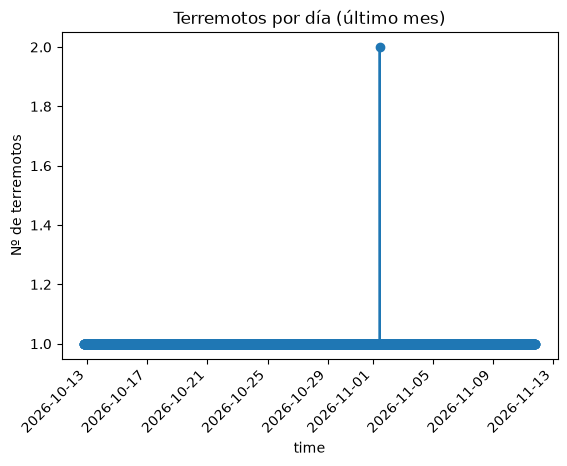

In [24]:
por_dia = terremotos["time"].value_counts().sort_index()
print(por_dia.head())

por_dia.plot(kind="line", marker="o")
plt.title("Terremotos por día (último mes)")
plt.ylabel("Nº de terremotos")
plt.xticks(rotation=45)
plt.show()

🧪 **Prueba:** copia la celda y quita `.sort_index()`. ¿Qué le pasa a la línea? ¿Por qué?

*Tu respuesta:*

## Paso 10 · Dispersión (página: `df.plot(kind='scatter', ...)`)
📌 **Tarea:** dibuja la **longitud** en el eje x y la **latitud** en el eje y. El color (`c`) y el tamaño (`s`) dependen de la magnitud.

c:\Python312\Lib\site-packages\matplotlib\collections.py:1121: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


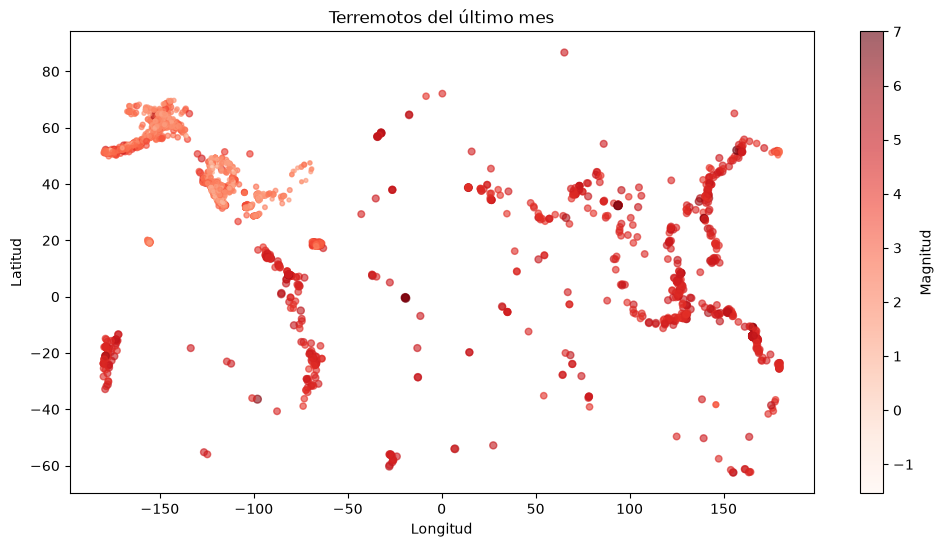

In [26]:
plt.figure(figsize=(12, 6))
plt.scatter(terremotos["longitude"], terremotos["latitude"],
            c=terremotos["mag"], cmap="Reds", s=terremotos["mag"] * 5, alpha=0.6)
plt.colorbar(label="Magnitud")
plt.xlabel("Longitud"); plt.ylabel("Latitud")
plt.title("Terremotos del último mes")
plt.show()

❓ **Pregunta 10:** no hemos dibujado ningún mapa, pero... ¿qué forma aparece? ¿Dónde se concentran los terremotos? ¿Qué hacen `c`, `s` y `alpha`?

*Tu respuesta:*

---
# Apartado 2 · Seaborn ("más elegante y estadístico")
## Paso 11 · `histplot` con curva
📌 **Tarea:** histograma de la magnitud con `kde=True`.
❓ **Pregunta 11:** ¿qué añade `kde=True` respecto al histograma del paso 7?

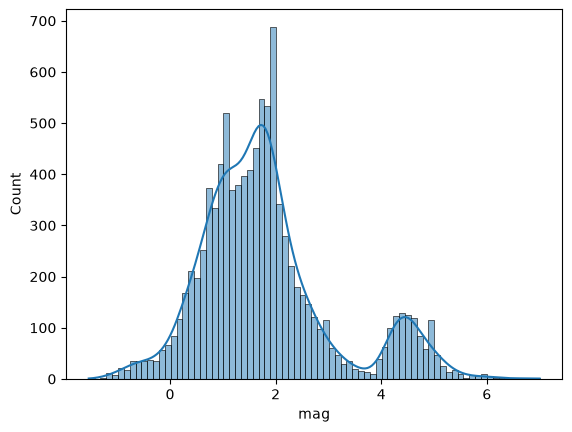

In [29]:
sns.histplot(terremotos["mag"], kde=True)
plt.show()

*Tu respuesta:* Añade la linea de la media del conteo de los terremotos

## Paso 12 · `boxplot` por grupos (página: `sns.boxplot(x='genero', y='ingreso', data=df)`)
📌 **Tarea:** una caja de magnitudes **por cada tipo** de evento.

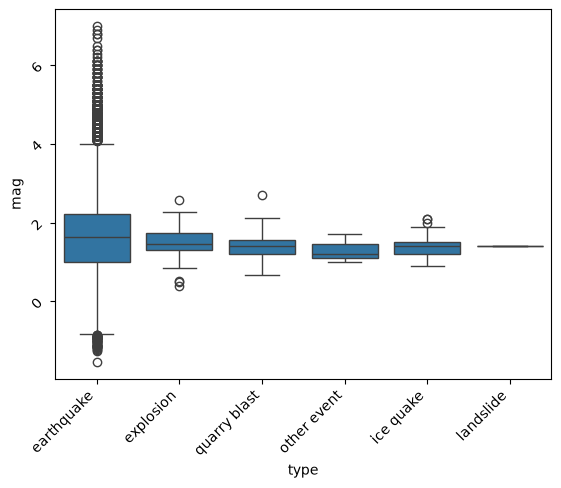

In [33]:
sns.boxplot(x="type", y="mag", data=terremotos)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=45)
plt.show()

❓ **Pregunta 12:** ¿las explosiones de cantera (`quarry blast`) son más fuertes o más débiles que los terremotos?

*Tu respuesta:* Son más debiles

## Paso 13 · Heatmap de correlaciones (con error a propósito)
📌 **Tarea en dos pasos:**
1. Ejecuta la primera celda **tal cual viene en la página**. Da error. Lee la última línea: ¿qué valor no puede convertir?
2. Arréglalo en la segunda celda usando solo las columnas numéricas.

In [ ]:
# Paso 1: da error a propósito
sns.heatmap(terremotos.corr(), annot=True, cmap="coolwarm")

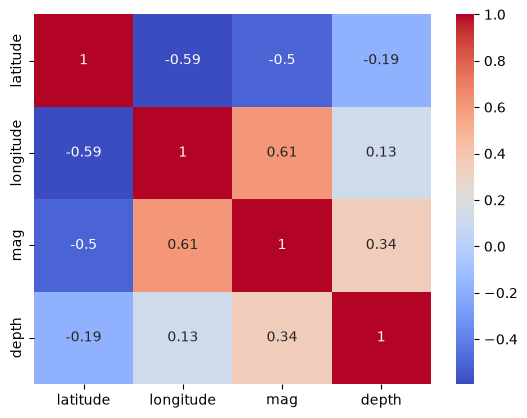

In [36]:
# Paso 2: arreglo
cols = ["latitude", "longitude", "mag", "depth"]
sns.heatmap(terremotos[cols].corr(), annot=True, cmap="coolwarm")
plt.show()

❓ **Pregunta 13:** ¿por qué falla el paso 1? Según el número del heatmap, ¿la magnitud está relacionada con la profundidad? (Recuerda: cerca de 1 o -1 = mucha relación; cerca de 0 = poca)

*Tu respuesta:* El paso 1 falla debido a que no se puede convertir de string, deben ser datos numericos.
Si, se relaciona con la profundidad, más no lo suficiente como para ser 100% correlativo.

---
# Apartado 3 · Visualización en Big Data
Con millones de filas no se puede (ni hace falta) dibujarlo todo: se usan herramientas como Dask, Spark, Tableau o Power BI, o se dibuja **una muestra**.
## Paso 14 · Dibujar solo 1000 terremotos
📌 **Tarea:** toma una muestra aleatoria de 1000 filas con `sample` y repite la dispersión.

(1000, 22)


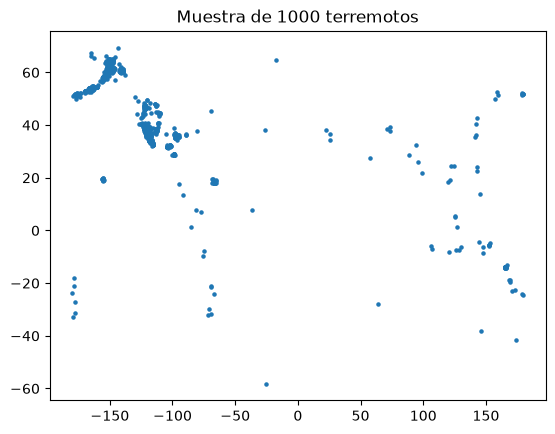

In [41]:
muestra = terremotos.sample(1000, random_state=10)
print(muestra.shape)
plt.scatter(muestra["longitude"], muestra["latitude"], s=5)
plt.title("Muestra de 1000 terremotos")
plt.show()

❓ **Pregunta 14:** ¿se sigue viendo la forma del mapa? ¿Para qué sirve `random_state=1`?

*Tu respuesta:* sirve para garantizar la reproducibilidad de los resuitlados, es decir, le indico a pandas que seleccione siempre el mismo numero de terremotos. Si no lo tuviera, seleccionaria de manera aleatoria, cambiando la forma del grafico

---
# Reto · Terremotos cerca de la Península (repasa máscaras para el examen)
📌 **Tarea:** latitud **entre 35 y 44** y longitud **entre -10 y 5**. ¿Cuántos hay? Muestra los 5 más fuertes.
💡 **Pista:** `between(a, b)`, cada condición entre paréntesis y `&`.

In [ ]:
peninsula = terremotos[(terremotos["latitude"].between(-55, -21.7)) &
                       (terremotos["longitude"].between(-73.6, -53.6))]
print(len(peninsula))
peninsula[["time", "mag", "place"]].sort_values("mag", ascending=False).head()

# Ante la ausencia de datos he probado con otras latitudes/longitudes para ver q funcione

35


,time,mag,place
57,2026-11-11 11:36:51.281000+00:00,5.1,"27 km WSW of Calama, Chile"
2968,2026-11-01 05:31:54.598000+00:00,4.8,"71 km NNW of San Antonio de los Cobres, Argentina"
4277,2026-10-28 07:02:12.084000+00:00,4.7,"39 km SSW of Serrezuela, Argentina"
4773,2026-10-26 20:20:25.411000+00:00,4.7,"7 km SE of Coquimbo, Chile"
9314,2026-10-14 00:30:47.698000+00:00,4.7,"94 km NNW of Coquimbo, Chile"


---
## Para terminar · Completa la tabla con tus palabras
| Función | ¿Para qué sirve? |
|---|---|
| `info()` | |
| `describe()` | |
| `value_counts()` | |
| `idxmax()` + `loc` | |
| `hist(bins=…)` | |
| `boxplot(column=…)` | |
| `plt.scatter(x, y, c=…, s=…)` | |
| `sns.heatmap(df.corr(), annot=True)` | |
| `sample(n)` | |